# 06 — Model experimentation and comparison

**Purpose:** document candidate-model experiments and hyperparameter tuning for the four-week aggregate demand task.

This notebook is an educational experimentation notebook. The final released model and its authoritative training/evaluation report are produced by `src/stockout_radar/training.py` and `reports/metrics/training_evaluation.json`. The notebook's candidate settings are not guaranteed to reproduce the production artifact byte-for-byte.

Unlike the earlier notebook draft, this version uses the production calendar-based train/validation/test split. Cross-validation folds are grouped by unique calendar weeks and use a four-week gap; they do not split products from the same week across folds. The held-out test set is not used for hyperparameter selection.

**Safety:** this notebook does not overwrite `models/gb_model.joblib` or `models/stockout_radar_v1.joblib`.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

sys.path.insert(0, str(Path("../src").resolve()))
from stockout_radar.training import load_training_data, chronological_split

model_df = load_training_data()
train, val, test, split_info = chronological_split(model_df)

features = [
    "units_lag1", "units_lag2", "units_lag4",
    "units_mean4", "units_std4", "units_mean8", "units_std8",
    "orders_lag1", "orders4", "price_lag1", "price_change4",
    "trend_ratio", "week_of_year", "month", "weeks_to_xmas",
    "product_age",
]

X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
X_test, y_test = test[features], test["target"]

print("Split:", split_info)
print("Train/validation/test shapes:", X_train.shape, X_val.shape, X_test.shape)

def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_true
    denominator = np.abs(y_true).sum()
    wape_percent = np.abs(error).sum() / denominator * 100 if denominator > 0 else np.nan
    return {
        "MAE (units)": float(np.abs(error).mean()),
        "RMSE (units)": float(np.sqrt(np.mean(error ** 2))),
        "WAPE (%)": float(wape_percent),
    }

Split: {'train_start': '2010-02-01', 'train_end': '2011-04-25', 'validation_start': '2011-05-23', 'validation_end': '2011-08-01', 'test_start': '2011-08-29', 'test_end': '2011-11-07', 'embargo_weeks': 4}
Train/validation/test shapes: (236926, 16) (46123, 16) (48511, 16)


## Initial candidate models

The candidate set includes linear regression, Ridge regression, Random Forest regression, and HistGradientBoosting regression with its default squared-error loss. The estimator name is stated explicitly because `HistGradientBoostingRegressor` is not the older `GradientBoostingRegressor` class.

In [2]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42,
    ),
    "HistGradientBoosting (squared-error loss)": HistGradientBoostingRegressor(
        loss="squared_error",
        random_state=42,
    ),
}

validation_results = {}
for model_name, estimator in models.items():
    estimator.fit(X_train, y_train)
    validation_results[model_name] = evaluate(y_val, estimator.predict(X_val))

pd.DataFrame(validation_results).T.sort_values("MAE (units)")

,MAE (units),RMSE (units),WAPE (%)
HistGradientBoosting (squared-error loss),45.785009,147.485204,59.035506
Ridge,46.890944,140.186409,60.461506
Linear Regression,46.900489,140.189022,60.473814
Random Forest,49.445192,145.738933,63.754971


The validation metrics allow candidate comparison on the same dates. A simple moving-average benchmark remains important: a more complex model is useful only if it improves on a reasonable baseline and behaves acceptably across products, not merely because it is more sophisticated.

In [3]:
# Experiment with absolute-error loss.
gb_mae = HistGradientBoostingRegressor(
    loss="absolute_error",
    random_state=42,
)
gb_mae.fit(X_train, y_train)
print(evaluate(y_val, gb_mae.predict(X_val)))

{'MAE (units)': 38.60434747648837, 'RMSE (units)': 140.74978981864123, 'WAPE (%)': 49.77671169115942}


In [4]:
# Experiment with a log1p-transformed target.
gb_log = HistGradientBoostingRegressor(random_state=42)
gb_log.fit(X_train, np.log1p(y_train))
log_predictions = np.expm1(gb_log.predict(X_val)).clip(min=0)
print(evaluate(y_val, log_predictions))

{'MAE (units)': 39.50535906099627, 'RMSE (units)': 145.41175009340245, 'WAPE (%)': 50.93848223785133}


## Date-grouped, embargo-aware hyperparameter tuning

Cross-validation is performed on the sorted list of distinct training weeks, not individual product rows. `gap=4` leaves four weekly origins between each fold's training and validation sections. The corresponding row indices are then built from whole weeks, so products sharing a week remain in the same fold.

In [5]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

unique_train_weeks = pd.DatetimeIndex(sorted(train["week"].unique()))
week_cv = TimeSeriesSplit(n_splits=3, gap=4)
cv_splits = []

for fold_train_positions, fold_valid_positions in week_cv.split(unique_train_weeks):
    fold_train_weeks = unique_train_weeks[fold_train_positions]
    fold_valid_weeks = unique_train_weeks[fold_valid_positions]

    row_train = np.flatnonzero(train["week"].isin(fold_train_weeks).to_numpy())
    row_valid = np.flatnonzero(train["week"].isin(fold_valid_weeks).to_numpy())

    assert set(fold_train_weeks).isdisjoint(set(fold_valid_weeks))
    assert fold_train_weeks.max() < fold_valid_weeks.min()
    cv_splits.append((row_train, row_valid))

print("Number of grouped CV folds:", len(cv_splits))
for i, (tr_idx, va_idx) in enumerate(cv_splits, start=1):
    print(
        f"Fold {i}: train rows={len(tr_idx):,}, validation rows={len(va_idx):,}, "
        f"last train week={train.iloc[tr_idx]['week'].max().date()}, "
        f"first validation week={train.iloc[va_idx]['week'].min().date()}"
    )

Number of grouped CV folds: 3
Fold 1: train rows=39,126, validation rows=57,813, last train week=2010-04-26, first validation week=2010-05-31
Fold 2: train rows=95,891, validation rows=61,531, last train week=2010-08-16, first validation week=2010-09-20
Fold 3: train rows=156,316, validation rows=64,730, last train week=2010-12-06, first validation week=2011-01-10


In [6]:
param_dist = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 400],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 10.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(loss="absolute_error", random_state=42),
    param_dist,
    n_iter=12,
    cv=cv_splits,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    refit=True,
)

search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print("Grouped CV MAE:", -search.best_score_)

Best parameters: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 1.0}
Grouped CV MAE: 59.68220743418772


In [7]:
best = search.best_estimator_
print("Validation metrics:", evaluate(y_val, best.predict(X_val)))

Validation metrics: {'MAE (units)': 38.501730959578424, 'RMSE (units)': 140.6207845461634, 'WAPE (%)': 49.644397247039144}


## Refit and evaluate on the untouched test period

After selecting hyperparameters using training-only grouped cross-validation and reviewing validation results, the experimental estimator is refitted on the combined training and validation periods. The test period remains untouched until this final evaluation.

In [8]:
fit_data = pd.concat([train, val], ignore_index=True)
experimental_final = clone(best)
experimental_final.fit(fit_data[features], fit_data["target"])

# Evaluate baselines, experimental estimator, and the released production artifact
# on the exact same held-out test observations.
test_results = {
    "Naive (4 x lag1)": evaluate(y_test, 4 * test["units_lag1"]),
    "Moving average (4 x mean4)": evaluate(y_test, 4 * test["units_mean4"]),
    "Experimental tuned HistGradientBoosting": evaluate(
        y_test, experimental_final.predict(X_test)
    ),
}

production_model = joblib.load("../models/stockout_radar_v1.joblib")
test_results["Released production model"] = evaluate(
    y_test, production_model.predict(X_test)
)

pd.DataFrame(test_results).T

,MAE (units),RMSE (units),WAPE (%)
Naive (4 x lag1),83.902620,326.141218,67.625337
Moving average (4 x mean4),66.108470,236.227163,53.283290
Experimental tuned HistGradientBoosting,59.973801,243.208930,48.338759
Released production model,59.224398,236.049122,47.734742


## Error analysis

The following diagnostics inspect the experimental estimator's test errors. Large residuals often occur around unusual high-volume orders. They should be interpreted alongside the complete holdout report and product-level metrics.

In [9]:
error_results = test[["StockCode", "week", "target"]].copy()
error_results["pred"] = experimental_final.predict(X_test).clip(min=0)
error_results["error"] = error_results["pred"] - error_results["target"]
error_results["abs_error"] = error_results["error"].abs()
error_results["last4_avg"] = test["units_mean4"] * 4
error_results["age"] = test["product_age"]

error_results.sort_values("abs_error", ascending=False).head(10)

,StockCode,week,target,pred,error,abs_error,last4_avg,age
345767,23084,2011-10-24,15190.0,177.700669,-15012.299331,15012.299331,448.0,24
354682,23084,2011-11-07,13728.0,1949.008243,-11778.991757,11778.991757,8282.0,26
353840,22197,2011-11-07,13275.0,2643.267417,-10631.732583,10631.732583,5979.0,100
341350,23084,2011-10-17,10925.0,314.799991,-10610.200009,10610.200009,469.0,23
350206,23084,2011-10-31,11940.0,1645.737083,-10294.262917,10294.262917,5983.0,25
349365,22197,2011-10-31,11156.0,2596.581234,-8559.418766,8559.418766,5658.0,99
344927,22197,2011-10-24,10976.0,2558.253056,-8417.746944,8417.746944,4558.0,98
336942,23084,2011-10-10,8282.0,539.752964,-7742.247036,7742.247036,479.0,22
340510,22197,2011-10-17,8995.0,2565.525871,-6429.474129,6429.474129,4076.0,97
346729,84077,2011-10-24,8639.0,2291.321415,-6347.678585,6347.678585,3702.0,98


In [10]:
# Share of total absolute error contributed by the largest 1% of rows.
top_count = max(1, int(len(error_results) * 0.01))
top_1_percent_error = error_results.nlargest(top_count, "abs_error")["abs_error"].sum()
share = top_1_percent_error / error_results["abs_error"].sum()
print("Share of total absolute error from top 1% of rows:", round(share, 3))

print("Mean absolute error by test week:")
print(error_results.groupby("week")["abs_error"].mean().round(1))
print("Under-forecast share:", (error_results["error"] < 0).mean().round(3))

Share of total absolute error from top 1% of rows: 0.273
Mean absolute error by test week:
week
2011-08-29    52.4
2011-09-05    57.4
2011-09-12    62.6
2011-09-19    60.3
2011-09-26    55.9
2011-10-03    59.6
2011-10-10    57.1
2011-10-17    64.2
2011-10-24    66.2
2011-10-31    63.4
2011-11-07    60.5
Name: abs_error, dtype: float64
Under-forecast share: 0.348


In [11]:
# Map selected high-error product codes to their descriptions.
descriptions = (
    pd.read_csv("../data/processed/clean_transactions.csv", dtype={"StockCode": str})
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
)

for product_code in ["23084", "22197", "84077"]:
    print(product_code, "->", descriptions.get(product_code))

23084 -> RABBIT NIGHT LIGHT
22197 -> POPCORN HOLDER , SMALL 
84077 -> WORLD WAR 2 GLIDERS ASSTD DESIGNS


In [12]:
# Largest over-forecasts have positive (prediction - actual) errors.
error_results.sort_values("error", ascending=False).head(5)

,StockCode,week,target,pred,error,abs_error,last4_avg,age
335915,21977,2011-10-10,644.0,2046.749551,1402.749551,1402.749551,2282.0,96
348524,21181,2011-10-31,301.0,1654.742621,1353.742621,1353.742621,1949.0,99
345642,22950,2011-10-24,127.0,1382.173925,1255.173925,1255.173925,1042.0,58
340462,22147,2011-10-17,87.0,1308.203628,1221.203628,1221.203628,2489.0,97
336817,22950,2011-10-10,567.0,1618.881420,1051.881420,1051.881420,1838.0,56


<Axes: title={'center': 'Product 23084 weekly units'}, xlabel='week'>

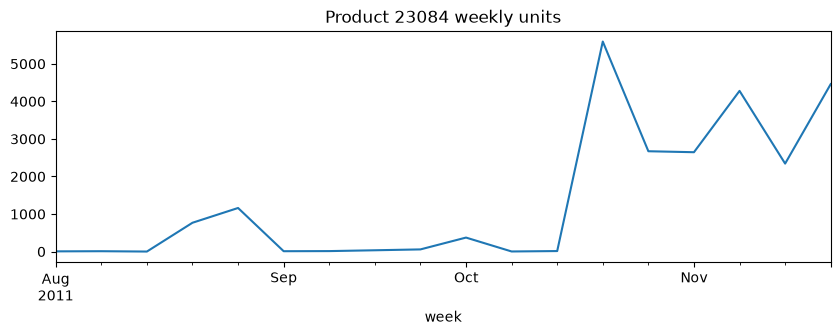

In [13]:
panel = pd.read_csv(
    "../data/processed/weekly_panel.csv",
    parse_dates=["week"],
    dtype={"StockCode": str},
)
product_code = "23084"
product_history = panel[panel["StockCode"] == product_code].set_index("week")["units"]
product_history.loc["2011-08-01":].plot(
    figsize=(10, 3),
    title=f"Product {product_code} weekly units",
)

<Axes: title={'center': 'Exploratory permutation importance (increase in MAE)'}>

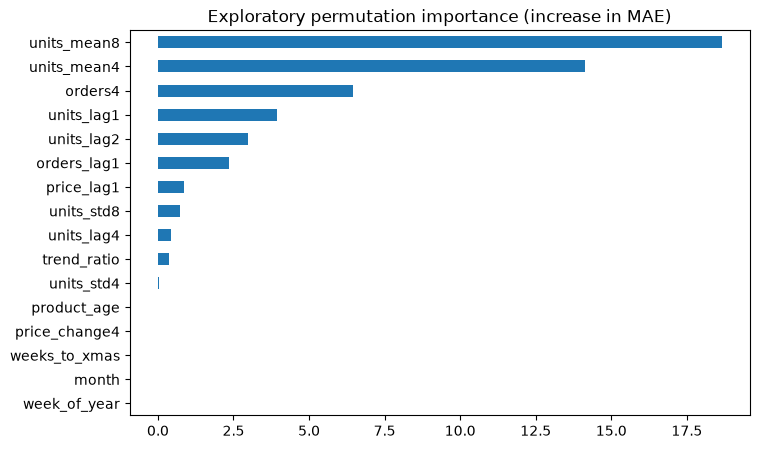

In [14]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best,
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1,
)

importance_series = pd.Series(
    importance.importances_mean,
    index=features,
).sort_values()
importance_series.plot(
    kind="barh",
    figsize=(8, 5),
    title="Exploratory permutation importance (increase in MAE)",
)

## Model artifact handling

This notebook deliberately does **not** save or overwrite a model artifact. The released application loads `models/stockout_radar_v1.joblib`, which is generated by `src/stockout_radar/training.py`. The older `models/gb_model.joblib` is retained as a reference artifact. Keep notebook experiments separate from both project artifacts.

In [15]:
print("Exploratory model remains in this notebook session only.")
print("Production artifact:", "../models/stockout_radar_v1.joblib")
print("No model files were overwritten.")

Exploratory model remains in this notebook session only.
Production artifact: ../models/stockout_radar_v1.joblib
No model files were overwritten.


## Residual quantile is not the deployed safety-stock input

The following residual quantile is an exploratory statistic only. The deployed inventory engine does not derive safety stock from this notebook. In the application, an operator supplies `safety_stock`; the inventory engine then uses that value in its reorder-point and target-stock calculations.

In [16]:
validation_residuals = y_val - best.predict(X_val)
residual_80th_percentile = validation_residuals.quantile(0.80)
print("Exploratory 80th percentile of signed validation residuals:", residual_80th_percentile)

Exploratory 80th percentile of signed validation residuals: 11.986432553940025


## Authoritative production training reference

For the exact candidate configuration, validation-based selection, refitting procedure, released model artifact and saved training metrics, refer to:

- `src/stockout_radar/training.py`
- `reports/metrics/training_evaluation.json`
- `reports/metrics/holdout_evaluation.json`

The released production model achieved MAE 59.2246 units, RMSE 236.0493 units and WAPE 47.7349% on 48,511 historical test observations. The moving-average baseline achieved MAE 66.1085, RMSE 236.2272 and WAPE 53.2833%. These are retrospective results on 2009–2011 data, not current-market performance guarantees.